In [ ]:

!pip install -q keras-tuner

In [ ]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks
import keras_tuner as kt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)
import joblib

SEED = 42
keras.utils.set_random_seed(SEED)   # sets Python, NumPy and TensorFlow seeds
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Load Data & Exploratory Analysis

In [ ]:
DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"   # change if your file name/path differs
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
# TotalCharges is stored as text because some rows contain a blank space
print("Blank TotalCharges:", (df["TotalCharges"].str.strip() == "").sum())
print("Missing values:\n", df.isna().sum().sum())
print("\nChurn distribution:\n", df["Churn"].value_counts(normalize=True).round(3))

Blank TotalCharges: 11
Missing values:
 0

Churn distribution:
 Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


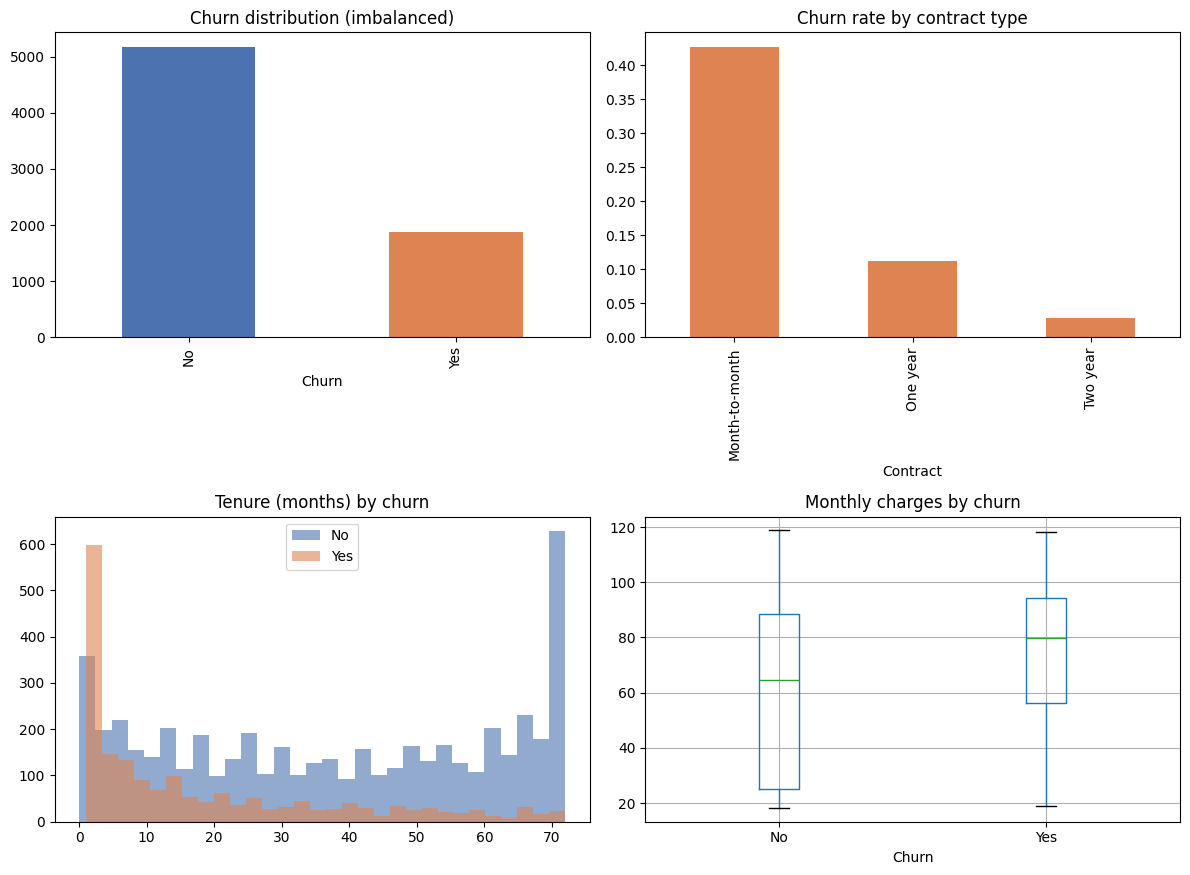

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

df["Churn"].value_counts().plot(kind="bar", ax=axes[0, 0], color=["#4C72B0", "#DD8452"])
axes[0, 0].set_title("Churn distribution (imbalanced)")

(df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean())
   .plot(kind="bar", ax=axes[0, 1], color="#DD8452"))
axes[0, 1].set_title("Churn rate by contract type")

for label, color in [("No", "#4C72B0"), ("Yes", "#DD8452")]:
    axes[1, 0].hist(df.loc[df["Churn"] == label, "tenure"], bins=30, alpha=0.6, label=label, color=color)
axes[1, 0].set_title("Tenure (months) by churn"); axes[1, 0].legend()

df.boxplot(column="MonthlyCharges", by="Churn", ax=axes[1, 1])
axes[1, 1].set_title("Monthly charges by churn")

plt.suptitle(""); plt.tight_layout(); plt.show()

**Observations:**
- About 26.5% of customers churn, so the classes are imbalanced. Accuracy alone is misleading, so we also track Recall, F1, ROC-AUC and PR-AUC.
- Month-to-month contracts, short tenure and high monthly charges are linked to churn.

## 2. Data Cleaning

In [ ]:
df = df.drop(columns=["customerID"])                         # identifier, no predictive value

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Rows with missing TotalCharges:", df["TotalCharges"].isna().sum(),
      "| their tenure:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())
# These are brand-new customers (tenure = 0) who have not been billed yet -> 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df.shape

Rows with missing TotalCharges: 11 | their tenure: [0]


(7043, 20)

## 3. Preprocessing: Split, Encode, Scale

In [ ]:
X = df.drop(columns=["Churn"])
y = df["Churn"].values

NUM_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT_COLS = [c for c in X.columns if c not in NUM_COLS]

# 70% train / 15% validation / 15% test, stratified to keep the churn ratio
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
])

# Fit ONLY on training data to avoid data leakage
X_train_p = preprocessor.fit_transform(X_train).astype("float32")
X_val_p   = preprocessor.transform(X_val).astype("float32")
X_test_p  = preprocessor.transform(X_test).astype("float32")
INPUT_DIM = X_train_p.shape[1]
print("Features after encoding:", INPUT_DIM)

# Class weights to handle imbalance (churners get a higher weight)
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
CLASS_WEIGHT = {0: weights[0], 1: weights[1]}
print("Class weights:", CLASS_WEIGHT)

Train: (4930, 19) Val: (1056, 19) Test: (1057, 19)
Features after encoding: 46
Class weights: {0: np.float64(0.680563224737714), 1: np.float64(1.8845565749235473)}


### 3.1 Reference model: Logistic Regression
A simple classical model, so we know whether the neural network adds value.

In [ ]:
log_reg = LogisticRegression(max_iter=2000, class_weight="balanced")
log_reg.fit(X_train_p, y_train)
lr_test_prob = log_reg.predict_proba(X_test_p)[:, 1]
print("Logistic Regression test ROC-AUC:", round(roc_auc_score(y_test, lr_test_prob), 4))

Logistic Regression test ROC-AUC: 0.8448


## 4. Model Design: ANN for Binary Classification

In [ ]:
def make_metrics():
    return [keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")]

def build_ann(input_dim, units=(64, 32), dropout=0.0, l2=0.0, lr=1e-3, batchnorm=False):
    """Fully-connected ANN. Regularization is switched on through the arguments."""
    reg = regularizers.l2(l2) if l2 > 0 else None
    model = keras.Sequential([keras.Input(shape=(input_dim,))])
    for u in units:
        model.add(layers.Dense(u, kernel_regularizer=reg))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))      # probability of churn
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy", metrics=make_metrics())
    return model

def plot_history(histories, metric="loss"):
    plt.figure(figsize=(6 * len(histories), 4))
    for i, (name, h) in enumerate(histories.items(), 1):
        plt.subplot(1, len(histories), i)
        plt.plot(h.history[metric], label="train")
        plt.plot(h.history["val_" + metric], label="validation")
        plt.title(f"{name} — {metric}"); plt.xlabel("Epoch"); plt.legend()
    plt.tight_layout(); plt.show()

### 4.1 Baseline ANN (no regularization)
A large network trained for many epochs with no regularization, to show overfitting.

In [ ]:
baseline = build_ann(INPUT_DIM, units=(256, 128, 64))
baseline.summary()

start = time.time()
hist_base = baseline.fit(X_train_p, y_train, validation_data=(X_val_p, y_val),
                         epochs=100, batch_size=32, class_weight=CLASS_WEIGHT, verbose=0)
print(f"Training time: {time.time() - start:.1f}s")

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 256)            │        12,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_14 (Activation)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,249 (208.00 KB)

 Trainable params: 53,249 (208.00 KB)

 Non-trainable params: 0 (0.00 B)

Training time: 87.3s


## 5. Regularization: L2 + Dropout + BatchNorm + Early Stopping

In [ ]:
regularized = build_ann(INPUT_DIM, units=(256, 128, 64), dropout=0.3, l2=1e-3, batchnorm=True)

early_stop = callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=15,
                                     restore_best_weights=True, verbose=1)
reduce_lr = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5,
                                        min_lr=1e-5, verbose=1)

start = time.time()
hist_reg = regularized.fit(X_train_p, y_train, validation_data=(X_val_p, y_val),
                           epochs=100, batch_size=32, class_weight=CLASS_WEIGHT,
                           callbacks=[early_stop, reduce_lr], verbose=0)
print(f"Stopped after {len(hist_reg.history['loss'])} epochs | time: {time.time() - start:.1f}s")

Epoch 18: early stopping
Restoring model weights from the end of the best epoch: 3.
Stopped after 18 epochs | time: 23.3s


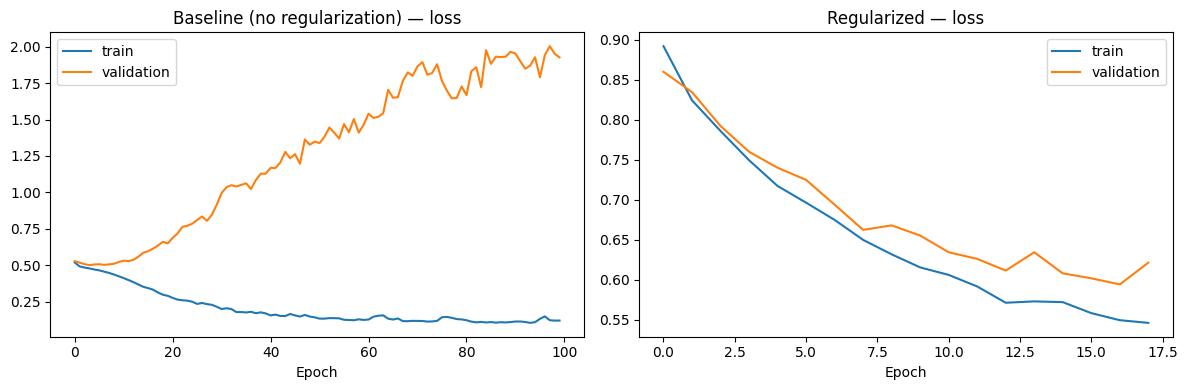

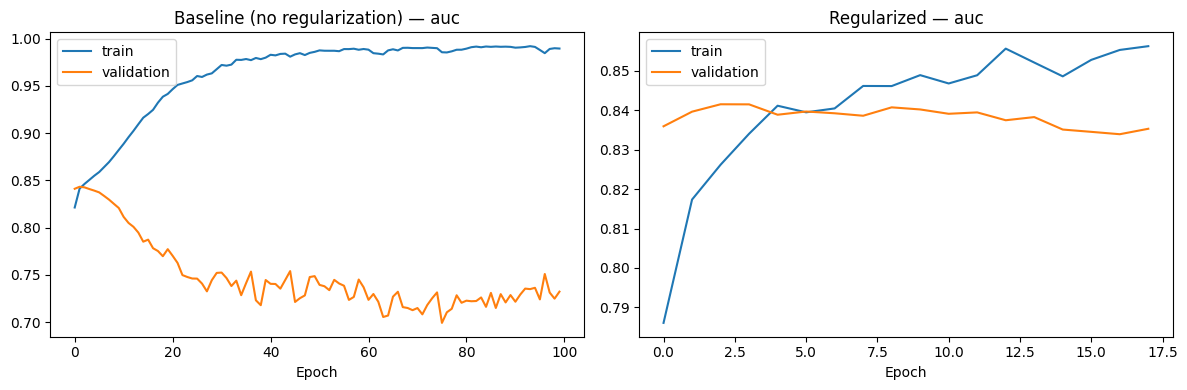

In [ ]:
plot_history({"Baseline (no regularization)": hist_base, "Regularized": hist_reg}, "loss")
plot_history({"Baseline (no regularization)": hist_base, "Regularized": hist_reg}, "auc")

## 6. Hyperparameter Tuning

### 6.1 Keras Tuner (Random Search)

In [ ]:
def tuner_model(hp):
    n_layers = hp.Int("n_layers", 1, 3)
    units = [hp.Choice(f"units_{i}", [32, 64, 128, 256]) for i in range(n_layers)]
    return build_ann(
        INPUT_DIM,
        units=units,
        dropout=hp.Float("dropout", 0.0, 0.5, step=0.1),
        l2=hp.Choice("l2", [0.0, 1e-4, 1e-3, 1e-2]),
        lr=hp.Choice("lr", [1e-2, 1e-3, 5e-4, 1e-4]),
        batchnorm=hp.Boolean("batchnorm"),
    )

tuner = kt.RandomSearch(
    tuner_model,
    objective=kt.Objective("val_auc", direction="max"),
    max_trials=20,
    executions_per_trial=1,
    directory="tuner_dir",
    project_name="telco_churn",
    overwrite=True,
    seed=SEED,
)
tuner.search_space_summary()

Search space summary
Default search space size: 6
n_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 128, 256], 'ordered': True}
dropout (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
l2 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.0001, 0.001, 0.01], 'ordered': True}
lr (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0005, 0.0001], 'ordered': True}
batchnorm (Boolean)
{'default': False, 'conditions': []}


In [ ]:
tuner.search(X_train_p, y_train,
             validation_data=(X_val_p, y_val),
             epochs=100, batch_size=32,
             class_weight=CLASS_WEIGHT,
             callbacks=[callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                                patience=10, restore_best_weights=True)],
             verbose=1)

tuner.results_summary(num_trials=5)
best_hp = tuner.get_best_hyperparameters(1)[0]
print("\nBest hyperparameters:", best_hp.values)

Trial 20 Complete [00h 00m 24s]
val_auc: 0.8412164449691772

Best val_auc So Far: 0.8469325304031372
Total elapsed time: 00h 10m 15s
Results summary
Results in tuner_dir/telco_churn
Showing 5 best trials
Objective(name="val_auc", direction="max")

Trial 12 summary
Hyperparameters:
n_layers: 2
units_0: 64
dropout: 0.30000000000000004
l2: 0.001
lr: 0.01
batchnorm: False
units_1: 32
units_2: 256
Score: 0.8469325304031372

Trial 05 summary
Hyperparameters:
n_layers: 3
units_0: 256
dropout: 0.0
l2: 0.0001
lr: 0.0005
batchnorm: False
units_1: 64
units_2: 128
Score: 0.8468819856643677

Trial 06 summary
Hyperparameters:
n_layers: 1
units_0: 256
dropout: 0.0
l2: 0.0001
lr: 0.01
batchnorm: False
units_1: 32
units_2: 64
Score: 0.8466172218322754

Trial 09 summary
Hyperparameters:
n_layers: 1
units_0: 256
dropout: 0.4
l2: 0.0001
lr: 0.01
batchnorm: False
units_1: 256
units_2: 256
Score: 0.8459568619728088

Trial 03 summary
Hyperparameters:
n_layers: 3
units_0: 64
dropout: 0.2
l2: 0.0001
lr: 0.01
b

### 6.2 Manual tuning: batch size
Keras Tuner above tunes the architecture and regularization. Here we tune batch size by hand using the best settings.

In [ ]:
batch_results = []
for bs in [16, 32, 64, 128]:
    keras.utils.set_random_seed(SEED)
    m = tuner.hypermodel.build(best_hp)
    t0 = time.time()
    h = m.fit(X_train_p, y_train, validation_data=(X_val_p, y_val),
              epochs=200, batch_size=bs, class_weight=CLASS_WEIGHT,
              callbacks=[callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                                 patience=15, restore_best_weights=True)],
              verbose=0)
    batch_results.append({"batch_size": bs,
                          "best_val_auc": max(h.history["val_auc"]),
                          "epochs": len(h.history["loss"]),
                          "time_s": round(time.time() - t0, 1)})

batch_df = pd.DataFrame(batch_results)
print(batch_df)
BEST_BATCH = int(batch_df.loc[batch_df["best_val_auc"].idxmax(), "batch_size"])
print("Best batch size:", BEST_BATCH)

   batch_size  best_val_auc  epochs  time_s
0          16      0.845329      22    31.2
1          32      0.845577      32    26.4
2          64      0.844859      21    14.6
3         128      0.846976      35    15.8
Best batch size: 128


### 6.3 Train the final model

In [ ]:
keras.utils.set_random_seed(SEED)
final_model = tuner.hypermodel.build(best_hp)
final_model.summary()

hist_final = final_model.fit(
    X_train_p, y_train, validation_data=(X_val_p, y_val),
    epochs=200, batch_size=BEST_BATCH, class_weight=CLASS_WEIGHT,
    callbacks=[callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=20,
                                       restore_best_weights=True),
               callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=7, min_lr=1e-5),
               callbacks.ModelCheckpoint("best_churn_model.keras", monitor="val_auc",
                                         mode="max", save_best_only=True)],
    verbose=0)

print("Epochs trained:", len(hist_final.history["loss"]))
plot_history({"Final tuned model": hist_final}, "loss")

## 7. Evaluation

In [ ]:
val_prob = final_model.predict(X_val_p, verbose=0).ravel()
prec, rec, thr = precision_recall_curve(y_val, val_prob)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
BEST_THRESHOLD = float(thr[np.argmax(f1s)])
print(f"Best threshold on validation: {BEST_THRESHOLD:.3f} (F1 = {f1s.max():.4f})")

Best threshold on validation: 0.528 (F1 = 0.6388)


In [43]:
def evaluate(name, y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {"Model": name, "Threshold": round(threshold, 3),
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, y_prob),
            "PR-AUC": average_precision_score(y_true, y_prob)}

test_probs = {
    "Logistic Regression": lr_test_prob,
    "ANN baseline": baseline.predict(X_test_p, verbose=0).ravel(),
    "ANN regularized": regularized.predict(X_test_p, verbose=0).ravel(),
    "ANN tuned": final_model.predict(X_test_p, verbose=0).ravel(),
}

rows = [evaluate(n, y_test, p) for n, p in test_probs.items()]
rows.append(evaluate("ANN tuned (best threshold)", y_test, test_probs["ANN tuned"], BEST_THRESHOLD))
results_df = pd.DataFrame(rows).set_index("Model").round(4)
results_df

,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,,
Logistic Regression,0.500,0.7483,0.5177,0.7794,0.6222,0.8448,0.6592
ANN baseline,0.500,0.7360,0.5031,0.5694,0.5342,0.7616,0.4852
ANN regularized,0.500,0.7389,0.5058,0.7794,0.6134,0.8377,0.6388
ANN tuned,0.500,0.7616,0.5371,0.7473,0.6250,0.8416,0.6546
ANN tuned (best threshold),0.528,0.7692,0.5493,0.7331,0.6280,0.8416,0.6546


              precision    recall  f1-score   support

        Stay       0.89      0.78      0.83       776
       Churn       0.55      0.73      0.63       281

    accuracy                           0.77      1057
   macro avg       0.72      0.76      0.73      1057
weighted avg       0.80      0.77      0.78      1057



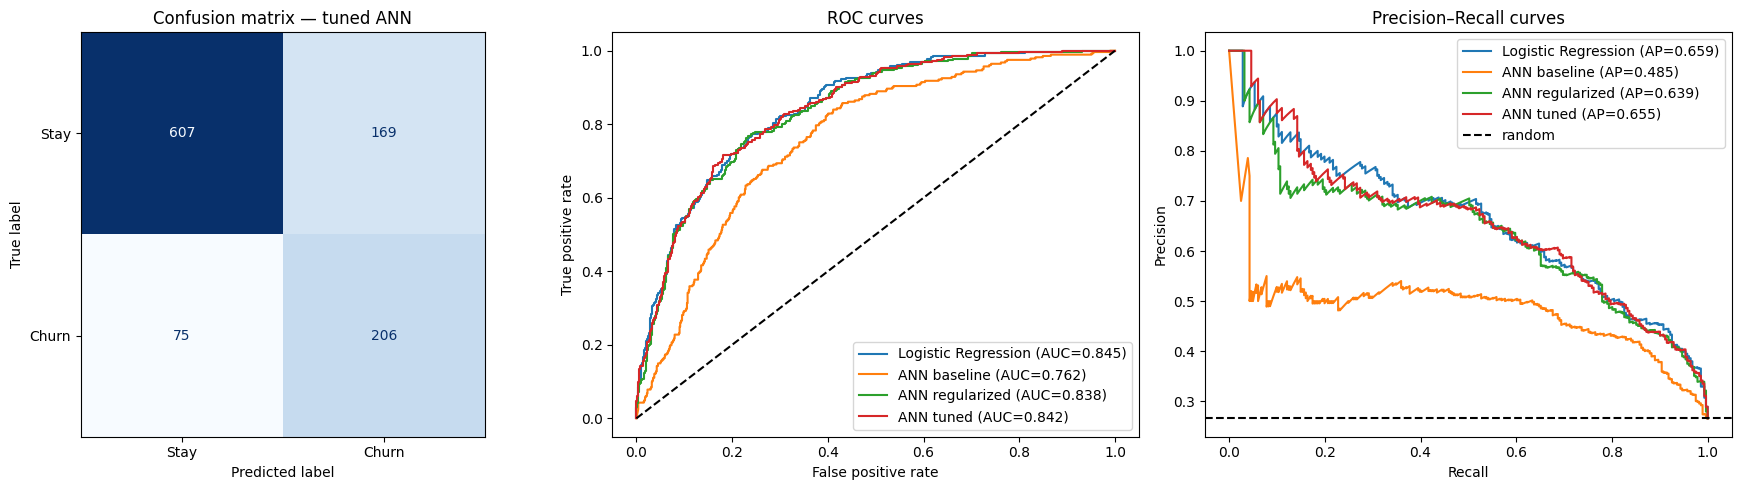

In [44]:
y_pred_final = (test_probs["ANN tuned"] >= BEST_THRESHOLD).astype(int)
print(classification_report(y_test, y_pred_final, target_names=["Stay", "Churn"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_final),
                       display_labels=["Stay", "Churn"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix — tuned ANN")

for name, p in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_title("ROC curves")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].legend()

for name, p in test_probs.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[2].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
axes[2].axhline(y_test.mean(), color="k", ls="--", label="random")
axes[2].set_title("Precision–Recall curves"); axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].legend()

plt.tight_layout(); plt.show()